# La batería de validación de cartera: backtest de cola, convergencia, aditividad, recursión frente a Monte Carlo, tamaño y potencia de la correlación

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 02 a 05 de este tema (el ajuste, las cópulas, CreditRisk+ y las contribuciones de Euler)
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este cuaderno puedes:

- nombrar las cinco pruebas de la batería de cartera, la hipótesis nula de cada una y la regla que convierte su resultado en una luz;
- correr cada prueba en un caso que debe aceptar y en un caso que debe rechazar, y ver qué devuelve el motor en ambos;
- decir qué no puede ver cada prueba: cuán pocos años necesita el backtest de cola para rechazar, qué significa una prueba de convergencia en verde para una cartera pequeña, qué es una tolerancia;
- leer el tamaño y la potencia de los estimadores de correlación en la grilla del simulador, con el error estándar de Monte Carlo y el intervalo de Wilson de cada tasa;
- leer juntas las filas versionadas de los cinco tipos de préstamo y de la grilla del simulador, y decir qué concluye un validador de ellas.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import math
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# El cuaderno está tres carpetas por debajo de la raíz del repositorio
ROOT = Path("../../..").resolve()

for name in ("riskvalidation", "numpy", "scipy", "matplotlib",):
    print(name, md.version(name))

# Mostrar un valor lógico o una etiqueta del motor en español, también dentro de listas y diccionarios
ETIQUETAS = {
    "green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada", "illustrative": "ilustrativa",
    "synthetic-calibrated": "sintética calibrada", "withheld-derived-only": "retenidas, solo derivados", "included": "incluidas",
    "fitted": "ajustado", "challenger-not-run": "retador no ejecutado",
}


def si_no(valor):
    if isinstance(valor, dict):
        return {ETIQUETAS.get(k, k): si_no(v) for k, v in valor.items()}
    if getattr(valor, 'ndim', 0) > 0:
        return si_no(valor.tolist())
    if isinstance(valor, (list, tuple)):
        return [si_no(v) for v in valor]
    if isinstance(valor, str):
        return ETIQUETAS.get(valor, valor)
    return "sí" if valor else "no"

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Siete archivos del caso C10, todos versionados (propietario: este repositorio; los cinco archivos por tipo de préstamo descansan en la tabla `chgallsa` de la Reserva Federal, https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm, dominio público, clase de licencia `mirror-allowed`):

- los cinco archivos por tipo de préstamo `commercial-industrial.json`, `commercial-real-estate.json`, `residential.json`, `credit-cards.json` y `other-consumer.json` en `data/derived/C10/`: cada uno trae 15 filas de `tests` (un backtest de cola, doce filas de aditividad de Euler, una fila de convergencia y una de CreditRisk+), los parámetros ajustados y las contribuciones detrás de esas filas;
- `grid-22.json` y `grid-40.json`: la **grilla del simulador**, el tamaño y la potencia de los estimadores de correlación sobre fracciones de incumplimiento anuales sintéticas sorteadas con una correlación conocida (`truth_status` es `synthetic-known-truth`): una PD conocida de 2%, doce correlaciones conocidas de 0,02 a 0,24, una nula de 0,12, 400 réplicas cada una, series de 22 y 40 años. Cada archivo tiene 24 filas de `portfolio.correlation_size_power`, una por correlación y estimador.

La celda siguiente los carga y cuenta las filas de prueba versionadas por prueba y luz.

In [2]:
# Cargar los siete artefactos y contar las filas de prueba versionadas por prueba y luz
NAMES = {
    "commercial-industrial": "Comerciales e industriales",
    "commercial-real-estate": "Inmobiliario comercial",
    "residential": "Inmobiliario residencial",
    "credit-cards": "Tarjetas de crédito",
    "other-consumer": "Otro consumo",
}
read = lambda name: json.loads((ROOT / "data" / "derived" / "C10" / f"{name}.json").read_text(encoding="utf-8"))
docs = {k: read(k) for k in NAMES}
grids = {22: read("grid-22"), 40: read("grid-40")}

print("calculado con riskvalidation", {d["provenance"]["riskvalidation_version"] for d in [*docs.values(), *grids.values()]})
print(f"{'tipo de préstamo':26s} {'filas':>5s}  luces por prueba")
for key, label in NAMES.items():
    counts = Counter((t["test_id"].split(".")[1], t["light"]) for t in docs[key]["tests"])
    print(f"{label:26s} {len(docs[key]['tests']):5d}  " + ", ".join(f"{name}:{si_no(light)}={n}" for (name, light), n in sorted(counts.items())))
for years, g in grids.items():
    print(f"grilla {years} años: {len(g['tests'])} filas | verdad sintética: {g['provenance']['truth_status']} | PD conocida {g['outputs']['generator']['known_pd']} | rho nula {g['outputs']['generator']['null_rho']}")

calculado con riskvalidation {'0.7.0'}
tipo de préstamo           filas  luces por prueba
Comerciales e industriales    15  crp_recursion_vs_mc:verde=1, euler_additivity:verde=12, mc_convergence:verde=1, tail_backtest:verde=1
Inmobiliario comercial        15  crp_recursion_vs_mc:verde=1, euler_additivity:verde=12, mc_convergence:verde=1, tail_backtest:verde=1
Inmobiliario residencial      15  crp_recursion_vs_mc:verde=1, euler_additivity:verde=12, mc_convergence:rojo=1, tail_backtest:rojo=1
Tarjetas de crédito           15  crp_recursion_vs_mc:verde=1, euler_additivity:verde=12, mc_convergence:verde=1, tail_backtest:rojo=1
Otro consumo                  15  crp_recursion_vs_mc:verde=1, euler_additivity:verde=12, mc_convergence:rojo=1, tail_backtest:rojo=1
grilla 22 años: 24 filas | verdad sintética: synthetic-known-truth | PD conocida 0.02 | rho nula 0.12
grilla 40 años: 24 filas | verdad sintética: synthetic-known-truth | PD conocida 0.02 | rho nula 0.12


## Método

### Paso 1: el backtest de cola, y cuán pocos años necesita para rechazar

**H0:** el número de años de evaluación sobre el cuantil $q$ ajustado es Binomial$(n, 1-q)$; la alternativa es más años sobre él que lo que dice el ajuste. El valor p es la cola superior $P(X\ge\text{observado})$ al nivel primario de 99% (Vasicek, 2002; Gordy, 2003, https://doi.org/10.1016/S1042-9573(03)00040-8). **Luz:** verde cuando $p\ge0{,}05$, ámbar de 0,01 a 0,05, roja bajo 0,01, una puerta interna de Contraste y no un umbral regulatorio. Con $n=6$ años de evaluación la prueba tiene poca potencia al 99%: un solo año sobre el cuantil da $p=1-0{,}99^6=0{,}0585$, todavía verde. La celda siguiente toma la PD y la correlación ajustadas de los préstamos comerciales e industriales del artefacto y entrega a `tail_backtest` del motor tres series de seis años que construye: todos bajo el cuantil 99%, un año sobre él y dos años sobre él. Luego corre los años de evaluación reales de dos tipos de préstamo.

In [3]:
# Correr el backtest de cola en tres series construidas y en los años de evaluación reales de dos tipos de préstamo
from riskvalidation.engines.vasicek import lhp_quantile
from riskvalidation.validation.portfolio import tail_backtest

def fitted(key):
    fit = docs[key]["outputs"]["fit"]["maximum_likelihood"]
    return fit["pd"]["estimate"], fit["rho"]["estimate"]

pd_ci, rho_ci = fitted("commercial-industrial")
q99 = float(lhp_quantile(0.99, pd_ci, rho_ci))
print("cuantil 99% ajustado de los préstamos comerciales:", round(q99, 5), "| p de un año sobre, seis años:", round(1 - 0.99 ** 6, 4))

calm = np.full(6, 0.004)
for label, years_above in (("ninguno sobre", 0), ("un año sobre", 1), ("dos años sobre", 2)):
    series = calm.copy()
    series[:years_above] = 1.1 * q99
    res = tail_backtest(series, pd_ci, rho_ci, levels=(0.95, 0.99, 0.999), primary_level=0.99)
    print(f"{label:20s} observados {int(res.statistic)} | p {res.p_value:.4f} | luz {si_no(res.light.value)}")

for key in ("commercial-industrial", "residential"):
    rows = docs[key]["outputs"]["annual_rates"]
    realised = np.array([np.nan if r["loss_rate"] is None else r["loss_rate"] for r in rows if r["window"] == "evaluation"])
    pd_k, rho_k = fitted(key)
    res = tail_backtest(realised, pd_k, rho_k, levels=(0.95, 0.99, 0.999), primary_level=0.99)
    row = next(t for t in docs[key]["tests"] if t["test_id"] == "portfolio.tail_backtest")
    print(f"{NAMES[key]:26s} observados al 99% {int(res.statistic)} | p {res.p_value:.2e} | {si_no(res.light.value)} | versionado p {row['p_value']:.2e} {si_no(row['light'])}")

cuantil 99% ajustado de los préstamos comerciales: 0.03335 | p de un año sobre, seis años: 0.0585
ninguno sobre        observados 0 | p 1.0000 | luz verde
un año sobre         observados 1 | p 0.0585 | luz verde
dos años sobre       observados 2 | p 0.0015 | luz rojo
Comerciales e industriales observados al 99% 0 | p 1.00e+00 | verde | versionado p 1.00e+00 verde
Inmobiliario residencial   observados al 99% 5 | p 5.95e-10 | rojo | versionado p 5.95e-10 rojo


### Paso 2: la prueba de convergencia de Monte Carlo

**H0:** la estimación de Monte Carlo es igual al ancla analítica. El estadístico es $z=(\text{estimación}-\text{ancla})/\mathrm{ee}$ y el valor p es $2\,(1-\Phi(|z|))$, con los mismos cortes verde, ámbar y rojo. El ancla de la batería de cartera es el cuantil de la cartera grande del cuaderno 01, exacto solo para una cartera de muchísimos nombres idénticos: una cartera finita queda sobre él por granularidad, así que la prueba es para una cartera cercana al límite y no es un veredicto sobre una cartera real. Un error estándar no positivo o una entrada no finita da `not_evaluated`, nunca un número. La celda siguiente entrega a `mc_convergence` la estimación, el error estándar y el ancla versionados con la estimación movida 0,5, 2,3 y 3,5 errores estándar, y con un error estándar cero.

In [4]:
# Correr la prueba de convergencia en la fila versionada, en estimaciones movidas algunos errores estándar y en un error estándar cero
from riskvalidation.validation.portfolio import mc_convergence

row = next(t for t in docs["commercial-industrial"]["tests"] if t["test_id"] == "portfolio.mc_convergence")
est, se, anchor = row["extras"]["estimate"], row["extras"]["se"], row["extras"]["anchor"]
print("fila versionada:", row["segment"], "| z", round(row["statistic"], 3), "| p", round(row["p_value"], 4), "|", si_no(row["light"]))
for shift in (0.5, 2.3, 3.5):
    res = mc_convergence(anchor + shift * se, se, anchor, "var")
    print(f"estimación movida en {shift} errores estándar: z {res.statistic:.2f} | p {res.p_value:.4f} | {si_no(res.light.value)}")
res = mc_convergence(est, 0.0, anchor, "var")
print("error estándar cero:", si_no(res.light.value), "| p:", res.p_value, "|", "no lleva ningún número")

fila versionada: lhp-like-99.9 | z -0.544 | p 0.5866 | verde
estimación movida en 0.5 errores estándar: z 0.50 | p 0.6171 | verde
estimación movida en 2.3 errores estándar: z 2.30 | p 0.0214 | ámbar
estimación movida en 3.5 errores estándar: z 3.50 | p 0.0005 | rojo
error estándar cero: no evaluada | p: None | no lleva ningún número


### Paso 3: la aditividad de Euler, y qué es una tolerancia

**H0:** las contribuciones de Euler suman el total. El estadístico es la suma, la métrica es $|\text{suma}-\text{total}|/|\text{total}|$ y no hay valor p (una asignación suma o no suma, así que no hay ámbar): verde cuando la métrica es a lo más la tolerancia, roja sobre ella (Tasche, 2008, https://arxiv.org/abs/0708.2542). La **tolerancia es el parámetro de la prueba**, y se declara con el resultado: $10^{-6}$ para las contribuciones al ES, que suman por construcción, y 0,01 para las contribuciones al VaR por núcleo, que tienen sesgo en el borde. Un total cero da `not_evaluated`. La celda siguiente toma las contribuciones al ES versionadas de la cópula gaussiana de un factor al 99,9% y las prueba como están, luego con una contribución inflada en 0,5% y en 2%, y luego con una brecha de $10^{-4}$ bajo ambas tolerancias.

In [5]:
# Correr la prueba de aditividad en contribuciones al ES versionadas, en contribuciones infladas y bajo las dos tolerancias
from riskvalidation.validation.portfolio import euler_additivity

block = next(b for b in docs["commercial-industrial"]["outputs"]["euler"] if b["rung_method"] == "gaussian-copula-one-factor")
level = next(lv for lv in block["levels"] if lv["level"] == 0.999)
rc_es = np.array([r["rc_es"] for r in level["rows"]])
total = level["es_total"]

res = euler_additivity(rc_es, total, 1e-6)
print("contribuciones versionadas:", f"{rc_es.sum():,.2f}", "frente al total", f"{total:,.2f}", "| brecha", f"{res.metric:.1e}", "|", si_no(res.light.value))
for factor in (1.005, 1.02):
    inflated = rc_es.copy()
    inflated[0] *= factor
    res = euler_additivity(inflated, total, 0.01)
    print(f"primera contribución x {factor}: brecha {res.metric:.4f} | tolerancia 0.01: {si_no(res.light.value)}")
small_gap = rc_es * (1 + 1e-4)
for tol in (0.01, 1e-6):
    res = euler_additivity(small_gap, total, tol)
    print(f"todas las contribuciones x 1.0001, tolerancia {tol:g}: brecha {res.metric:.1e} | {si_no(res.light.value)}")
res = euler_additivity(rc_es, 0.0, 1e-6)
print("total cero:", si_no(res.light.value), "| métrica:", res.metric, "|", "no se puede calcular una brecha relativa")

contribuciones versionadas: 3,683,187.00 frente al total 3,683,187.00 | brecha 0.0e+00 | verde
primera contribución x 1.005: brecha 0.0028 | tolerancia 0.01: verde
primera contribución x 1.02: brecha 0.0111 | tolerancia 0.01: rojo
todas las contribuciones x 1.0001, tolerancia 0.01: brecha 1.0e-04 | verde
todas las contribuciones x 1.0001, tolerancia 1e-06: brecha 1.0e-04 | rojo
total cero: no evaluada | métrica: None | no se puede calcular una brecha relativa


### Paso 4: la recursión de CreditRisk+ frente a Monte Carlo

**H0:** la distribución de la recursión es la distribución de la muestra de Monte Carlo del mismo modelo. El estadístico es la distancia de Kolmogorov $D=\max_n|F_{\text{pmf}}(n)-F_{\text{MC}}(n)|$ y el valor p viene de la ley asintótica de Kolmogorov, $2\sum_{j\ge1}(-1)^{j-1}e^{-2j^2SD^2}$ (conservadora para una distribución discreta); la prueba es roja sea cual sea el valor p si alguna probabilidad de la recursión es negativa, y `not_evaluated` para menos de 10 escenarios o una muestra sobre la grilla. Reconstruimos el insumo de la recursión del cuaderno 04 y su muestra (100.000 escenarios), la probamos, y luego la rompemos dos veces: una recursión corrida con una varianza Gamma 50% demasiado alta (un modelo equivocado, que la prueba debe rechazar), y una copia de las probabilidades correctas con una entrada puesta ligeramente negativa (que la prueba debe marcar en rojo aunque su valor p no se mueva).

In [6]:
# Probar la recursión contra una muestra de su modelo, luego contra una varianza Gamma equivocada y contra una entrada negativa
from riskvalidation.portfolio import creditrisk_plus as cr
from riskvalidation.validation.portfolio import crp_recursion_vs_mc

book = docs["commercial-industrial"]["outputs"]["portfolio"]
crp = next(r for r in docs["commercial-industrial"]["outputs"]["rungs"] if r["id"] == "c4-creditrisk-plus")
sigma2 = next(p["value"] for p in crp["parameters"] if p["name"] == "sigma2")
loss_unit = next(p["value"] for p in crp["parameters"] if p["name"] == "loss_unit")
n_max = int(next(d["value"] for d in crp["diagnostics"] if d["name"] == "n_max"))
ead = np.concatenate([np.full(g["n_names"], g["ead_each"]) for g in book["groups"]])
pd_names = np.concatenate([np.full(g["n_names"], g["pd"]) for g in book["groups"]])
units = np.rint(ead * book["lgd_mean"] / loss_unit).astype(int)
make = lambda s2: cr.CreditRiskPlusInput(nu=units, pd=pd_names, w0=np.zeros(ead.size), weights=np.ones((ead.size, 1)), sigma2=np.array([s2]), loss_unit=loss_unit, currency=book["currency"])
pmf = cr.pmf_stable(make(sigma2), n_max)

rng = np.random.default_rng(np.random.PCG64(4006))
factor = rng.gamma(shape=1.0 / sigma2, scale=sigma2, size=100_000)
sample = np.zeros(factor.size, dtype=np.int64)
first = 0
for g in book["groups"]:
    sample += int(units[first]) * rng.poisson(g["n_names"] * g["pd"] * factor)
    first += g["n_names"]

wrong = cr.pmf_stable(make(1.5 * sigma2), n_max)
broken = pmf.copy()
broken[5] = -1e-6
for label, p in (("la recursión correcta", pmf), ("varianza Gamma x 1.5", wrong), ("una entrada negativa", broken)):
    res = crp_recursion_vs_mc(p, sample)
    print(f"{label:30s} D {res.statistic:.5f} | p {res.p_value:.3e} | {si_no(res.light.value)} | entradas negativas {res.extras['negative_entries']}")

la recursión correcta          D 0.00398 | p 8.429e-02 | verde | entradas negativas 0
varianza Gamma x 1.5           D 0.06677 | p 0.000e+00 | rojo | entradas negativas 0
una entrada negativa           D 0.00398 | p 8.416e-02 | rojo | entradas negativas 1


### Paso 5: el tamaño y la potencia de los estimadores de correlación

La última prueba es de otro tipo: evalúa un estimador, no un modelo. En la grilla del simulador, cada una de 400 réplicas sortea una serie de fracciones de incumplimiento anuales con una correlación conocida, estima la correlación con cada uno de los dos estimadores del cuaderno 02, y rechaza H0: $\rho=0{,}12$ cuando 0,12 queda fuera del intervalo al 95% del estimador. Con la correlación conocida 0,12 la tasa de rechazo es el **tamaño**, que debe ser igual al $\alpha=0{,}05$ nominal; con cualquier otra correlación conocida es la **potencia**. `correlation_size_power` del motor recibe los booleanos de una celda y devuelve la tasa, su error estándar de Monte Carlo $\sqrt{\hat r(1-\hat r)/R}$ y el intervalo de Wilson al 95% (Wilson, 1927, https://doi.org/10.1080/01621459.1927.10502953). En una celda de tamaño el estadístico es $(\hat r-\alpha)/\sqrt{\alpha(1-\alpha)/R}$ con un valor p normal de dos colas; verde desde 0,05, rojo bajo 0,01. En una celda de potencia la luz es verde desde una tasa de 0,80, ámbar desde 0,50, roja bajo: puertas de Contraste. La tasa depende solo de cuántas réplicas rechazaron, así que la celda siguiente reconstruye los booleanos a partir de los conteos versionados, recalcula la celda de tamaño de cada estimador en la grilla de 22 años y compara con las filas versionadas.

In [7]:
# Reconstruir los booleanos a partir de los conteos versionados, recalcular las celdas de tamaño y compararlas con las filas versionadas
from riskvalidation.validation.portfolio import correlation_size_power

gen = grids[22]["outputs"]["generator"]
print("simulador:", gen["name"], "| réplicas:", gen["n_replications"], "| largo de la serie:", gen["series_length_years"], "| nula rho:", gen["null_rho"], "| alpha:", gen["alpha"], "| semilla:", gen["seed"])
print(f"{'estimador':20s} {'tasa':>7s} {'error est.':>10s} {'Wilson 95%':>16s} {'p':>8s} {'luz':>6s} | {'tasa versionada':>20s} {'luz versionada':>20s}")
for row in grids[22]["tests"]:
    extras = row["extras"]
    if extras["role"] != "size":
        continue
    flags = np.arange(row["n"]) < row["n_events"]
    res = correlation_size_power(flags, extras["known_rho"], extras["null_rho"], alpha=extras["alpha"], estimator=extras["estimator"])
    print(f"{extras['estimator']:20s} {res.metric:7.4f} {res.extras['se']:10.4f} {res.extras['ci_low']:7.3f}-{res.extras['ci_high']:.3f} {res.p_value:8.2e} {si_no(res.light.value):>6s} | {row['metric']:20.4f} {si_no(row['light']):>20s}")

simulador: vasicek-lhp-simulator | réplicas: 400 | largo de la serie: 22 | nula rho: 0.12 | alpha: 0.05 | semilla: 7001
estimador               tasa error est.       Wilson 95%        p    luz |      tasa versionada       luz versionada
maximum-likelihood    0.0525     0.0112   0.035-0.079 8.19e-01  verde |               0.0525                verde
moments               0.1850     0.0194   0.150-0.226 3.02e-35   rojo |               0.1850                 rojo


La grilla es la imagen completa. La celda siguiente dibuja, para las grillas de 22 y de 40 años, la tasa de rechazo de cada estimador en cada correlación conocida con su intervalo de Wilson, el nivel nominal de 5%, la puerta de potencia de 80% y la correlación nula. Donde una curva es alta la prueba ve el apartamiento de 0,12; donde es baja un validador no puede distinguir esa correlación de 0,12 con tantos años.

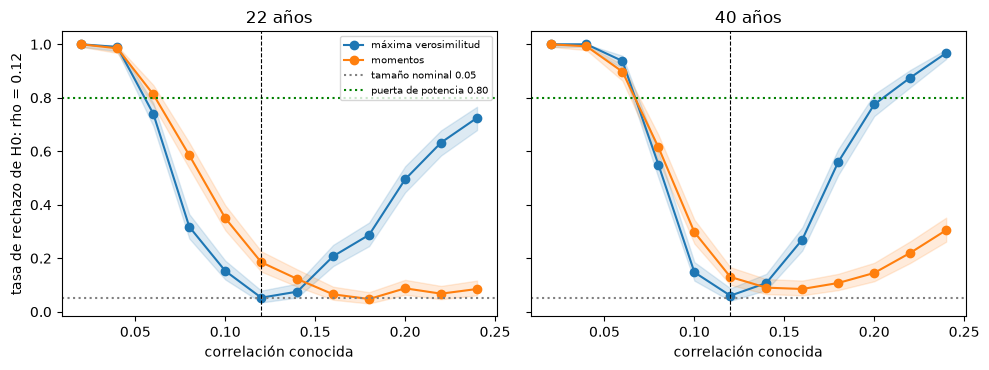

rho conocida   ML 22   ML 40  momentos 22  momentos 40
        0.02   1.000   1.000        1.000        1.000
        0.04   0.990   1.000        0.985        0.993
        0.06   0.740   0.938        0.812        0.897
        0.08   0.318   0.550        0.585        0.615
        0.10   0.152   0.147        0.350        0.297
        0.12   0.052   0.060        0.185        0.130  (nula)
        0.14   0.075   0.107        0.122        0.090
        0.16   0.207   0.270        0.065        0.085
        0.18   0.287   0.560        0.048        0.107
        0.20   0.495   0.775        0.087        0.145
        0.22   0.632   0.875        0.068        0.220
        0.24   0.725   0.968        0.085        0.305


In [8]:
# Dibujar la tasa de rechazo de cada estimador frente a la correlación conocida para las grillas de 22 y de 40 años
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, (years, g) in zip(axes, grids.items()):
    cells = g["outputs"]["cells"]
    for name, color, label in (("maximum-likelihood", "tab:blue", "máxima verosimilitud"), ("moments", "tab:orange", "momentos")):
        rho_known = np.array([c["known_rho"] for c in cells])
        picked = [next(e for e in c["estimators"] if e["estimator"] == name) for c in cells]
        rate = np.array([e["rejection_rate"] for e in picked])
        lo = np.array([e["rejection_ci_low"] for e in picked])
        hi = np.array([e["rejection_ci_high"] for e in picked])
        ax.plot(rho_known, rate, marker="o", color=color, label=label)
        ax.fill_between(rho_known, lo, hi, color=color, alpha=0.15)
    ax.axhline(0.05, color="gray", linestyle=":", label="tamaño nominal 0.05")
    ax.axhline(0.80, color="green", linestyle=":", label="puerta de potencia 0.80")
    ax.axvline(g["outputs"]["generator"]["null_rho"], color="black", linestyle="--", linewidth=0.8)
    ax.set_xlabel("correlación conocida")
    ax.set_title(f"{years} años")
axes[0].set_ylabel("tasa de rechazo de H0: rho = 0.12")
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()

# Las mismas tasas como tabla: máxima verosimilitud y momentos a 22 y 40 años
rates = {}
for years, g in grids.items():
    for row in g["tests"]:
        rates[(years, row["extras"]["estimator"], row["extras"]["known_rho"])] = row["metric"]
print(f"{'rho conocida':>12s} {'ML 22':>7s} {'ML 40':>7s} {'momentos 22':>12s} {'momentos 40':>12s}")
for rho_known in sorted({k[2] for k in rates}):
    mark = "  (nula)" if abs(rho_known - 0.12) < 1e-9 else ""
    print(f"{rho_known:12.2f} {rates[(22, 'maximum-likelihood', rho_known)]:7.3f} {rates[(40, 'maximum-likelihood', rho_known)]:7.3f} {rates[(22, 'moments', rho_known)]:12.3f} {rates[(40, 'moments', rho_known)]:12.3f}{mark}")

### Paso 6: leer la batería versionada

Un validador lee las filas juntas. La celda siguiente imprime, para los cinco tipos de préstamo, la luz del backtest de cola, cuántas de las doce filas de aditividad de Euler son verdes, y las luces de convergencia y recursión, a partir de los `tests` versionados. Luego cuenta las luces de las 24 filas de tamaño y potencia de cada grilla del simulador por estimador, de modo que todo el cuadro de tamaño y potencia sea una tabla.

In [9]:
# Imprimir las luces versionadas de los cinco tipos de préstamo y contar las luces de las grillas del simulador por estimador
print(f"{'tipo de préstamo':26s} {'cola':>6s} {'Euler verde':>14s} {'convergencia':>14s} {'CreditRisk+':>12s}")
for key, label in NAMES.items():
    by_id = {}
    for t in docs[key]["tests"]:
        by_id.setdefault(t["test_id"], []).append(t["light"])
    euler_lights = by_id["portfolio.euler_additivity"]
    z_conv = next(t["statistic"] for t in docs[key]["tests"] if t["test_id"] == "portfolio.mc_convergence")
    print(f"{label:26s} {si_no(by_id['portfolio.tail_backtest'][0]):>6s} {euler_lights.count('green'):>10d} de {len(euler_lights):<2d} {si_no(by_id['portfolio.mc_convergence'][0]):>8s} (z {z_conv:+6.1f}) {si_no(by_id['portfolio.crp_recursion_vs_mc'][0]):>12s}")

for years, g in grids.items():
    counts = Counter((t["extras"]["estimator"], t["extras"]["role"], t["light"]) for t in g["tests"])
    print(f"grilla {years} años:")
    for estimator in ("maximum-likelihood", "moments"):
        power = {light: counts.get((estimator, "power", light), 0) for light in ("green", "amber", "red")}
        size = next(t for t in g["tests"] if t["extras"]["estimator"] == estimator and t["extras"]["role"] == "size")
        print(f"  {estimator:20s} tamaño {size['metric']:.4f} ({si_no(size['light'])}) | celdas de potencia verde/ámbar/rojo: {power['green']}/{power['amber']}/{power['red']}")

tipo de préstamo             cola    Euler verde   convergencia  CreditRisk+
Comerciales e industriales  verde         12 de 12    verde (z   -0.5)        verde
Inmobiliario comercial      verde         12 de 12    verde (z   -1.5)        verde
Inmobiliario residencial     rojo         12 de 12     rojo (z  +23.4)        verde
Tarjetas de crédito          rojo         12 de 12    verde (z   +1.3)        verde
Otro consumo                 rojo         12 de 12     rojo (z   +7.7)        verde
grilla 22 años:
  maximum-likelihood   tamaño 0.0525 (verde) | celdas de potencia verde/ámbar/rojo: 2/3/6
  moments              tamaño 0.1850 (rojo) | celdas de potencia verde/ámbar/rojo: 3/1/7
grilla 40 años:
  maximum-likelihood   tamaño 0.0600 (verde) | celdas de potencia verde/ámbar/rojo: 5/3/3
  moments              tamaño 0.1300 (rojo) | celdas de potencia verde/ámbar/rojo: 3/1/7


## Resultados

- **El backtest de cola necesita dos años para rechazar al 99%, y los ajustes reales muestran el rango.** Con seis años de evaluación, ningún año sobre el cuantil 99% ajustado da p = 1,0 (verde), un año da p = 0,0585, todavía verde porque está sobre 0,05, y dos años dan p = 0,0015 (rojo). En los años de evaluación reales el ajuste comercial e industrial no tiene ninguno sobre (p = 1,0, verde, igual a la fila versionada) y el ajuste residencial tiene 5 de 6 (p = 6e-10, rojo, igual a la fila versionada). La prueba es una puerta sobre el ajuste frente a los años que le siguieron, y es la única de las cinco que se encuentra con resultados observados.
- **La prueba de convergencia aprueba o reprueba una cartera pequeña, no un modelo.** La fila comercial versionada está en z = -0,54 (p = 0,59, verde). Una estimación movida 0,5 errores estándar sigue en verde (p = 0,62), con 2,3 es ámbar (p = 0,021) y con 3,5 roja (p = 0,0005); un error estándar cero devuelve `not_evaluated` y ningún número. En las filas versionadas la cartera residencial está en rojo con z = +23,4 y otro consumo con z = +7,7, mientras que el inmobiliario comercial (z = -1,5) y las tarjetas de crédito (z = +1,3) están en verde. El cuaderno no prueba por qué ocurren los dos rojos; muestra solo que la comprobación de 5.000 nombres no alcanza el límite de la cartera grande con su PD y correlación, y un rojo aquí no dice que el motor esté equivocado.
- **Una tolerancia es parte del resultado.** Las contribuciones al ES versionadas suman el total exactamente (brecha 0, verde). Una contribución inflada en 0,5% deja una brecha de 0,0028, verde con la tolerancia de 0,01; inflada en 2% la brecha es 0,0111, roja. La misma brecha relativa de 1e-4 es verde con la tolerancia del VaR de 0,01 y roja con la del ES de 1e-6. Un total cero devuelve `not_evaluated`. Una fila de Euler en verde significa entonces que la asignación suma hasta la tolerancia declarada, no más.
- **La prueba de la recursión ve un modelo equivocado y una probabilidad negativa.** La recursión correcta frente a su propia muestra tiene D = 0,00398 y p = 0,084 (verde). Una varianza Gamma 50% demasiado alta da D = 0,0668 y un valor p de 0 (rojo). Una entrada puesta en -1e-6 deja D y p sin cambio y la luz pasa a roja, porque la regla marca en rojo toda probabilidad negativa sea cual sea el valor p.
- **La prueba de correlación de máxima verosimilitud tiene el tamaño correcto y poca potencia.** En el simulador con 22 años la prueba de máxima verosimilitud de rho = 0,12 rechaza el 5,25% de las veces cuando es cierta (error estándar 1,1 puntos, intervalo de Wilson de 3,5% a 7,9%, p = 0,82, verde) y la prueba de momentos rechaza el 18,5% de las veces (intervalo de 15,0% a 22,6%, p = 3e-35, rojo). Con 40 años los tamaños son 6,0% y 13,0%. Un validador que rechaza una correlación con el intervalo de momentos se equivoca cerca de una vez de cada cinco cuando la correlación es cierta.
- **Ninguna prueba tiene mucha potencia frente a sus vecinas.** Con 22 años la prueba de máxima verosimilitud rechaza una correlación verdadera de 0,10 solo el 15% de las veces y de 0,14 solo el 7,5%; para llegar a 80% necesita una correlación verdadera de 0,04 o menos, y sobre la nula nunca llega a 80% con 22 años (72,5% en 0,24). Con 40 años llega a 77,5% en 0,20 y 96,8% en 0,24. La prueba de momentos, que tiene sesgo a la baja, casi nunca rechaza correlaciones sobre 0,12 (4,8% a 8,7% de 0,16 a 0,24 con 22 años). De las 11 celdas de potencia con 22 años, la prueba de máxima verosimilitud está en verde en 2, en ámbar en 3 y en rojo en 6.
- **Leer juntos los cinco tipos de préstamo.** Las doce filas de aditividad de Euler de cada tipo de préstamo y la fila de CreditRisk+ están todas en verde: son puertas de consistencia que un motor correcto aprueba, y no pueden decirle a un validador que el modelo está equivocado. El backtest de cola está en rojo para residencial, tarjetas de crédito y otro consumo y en verde para los dos tipos comerciales, y esa separación, no las filas verdes, es la evidencia sobre las correlaciones ajustadas del cuaderno 02.

Lo que este cuaderno no muestra: un análisis de potencia del propio backtest de cola (seis años no pueden tener mucha), el tamaño de las otras cuatro pruebas, ni el efecto de años dependientes en cualquiera de ellas.

## Resumen

- La batería de cartera tiene cinco pruebas: el backtest de cola (binomial sobre años sobre un cuantil ajustado), la prueba de convergencia de Monte Carlo (z frente a un ancla analítica), la aditividad de Euler (una suma dentro de una tolerancia), la recursión de CreditRisk+ frente a Monte Carlo (distancia de Kolmogorov, roja con una entrada negativa) y el tamaño y la potencia de un estimador de correlación.
- Cada una devuelve un `TestResult` con su hipótesis nula, sus parámetros y una luz bajo puertas de Contraste; un resultado que no se puede evaluar es `not_evaluated`, nunca un número.
- Las pruebas de consistencia las aprueba un motor correcto, y el backtest de cola es la que se encuentra con los resultados y separa los tipos de préstamo.
- La prueba de correlación de máxima verosimilitud tiene el tamaño correcto y poca potencia con 22 años; la prueba de momentos rechaza de más en la nula y casi nunca rechaza sobre ella.

**Qué probar a continuación.** Planta tu propio defecto: mueve un año del backtest de cola, cambia la tolerancia de la prueba de aditividad, o dale a `crp_recursion_vs_mc` otro largo de grilla, y mira qué prueba se pone en rojo primero. Luego lee el cuaderno 07 para el estado del arte en que estas pruebas se ubican.

## Referencias

- Wilson, E. B. (1927), Probable inference, the law of succession, and statistical inference, Journal of the American Statistical Association 22(158):209-212. https://doi.org/10.1080/01621459.1927.10502953
- Tasche, D. (2008), Capital allocation to business units and sub-portfolios: the Euler principle, arXiv 0708.2542. https://arxiv.org/abs/0708.2542
- Haaf, H., Reiss, O. y Schoenmakers, J. (2004), Numerically stable computation of CreditRisk+, Journal of Risk 6(4):1-10. https://doi.org/10.21314/jor.2004.097
- Gordy, M. B. (2003), A risk-factor model foundation for ratings-based bank capital rules, Journal of Financial Intermediation 12(3):199-232. https://doi.org/10.1016/S1042-9573(03)00040-8
- Board of Governors of the Federal Reserve System, Charge-off and delinquency rates on loans and leases at commercial banks, table chgallsa (public domain; licence class mirror-allowed). https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm
- Vasicek, O. (2002), Loan portfolio value, Risk, December 2002, 160-162.
- Kolmogorov, A. (1933) and Smirnov, N. (1948), the Kolmogorov distance and its asymptotic law, as cited by the engine's `validation.portfolio` module.
- Persisted research dossier 05 of this product (the validation of an economic capital model), section G.5, and dossier 04, section C.4.
- The engine's contract for these functions: `docs/contracts/engine/` of this repository.